In [2]:
!pip install pymatgen
import pymatgen
print("pymatgen installed:", pymatgen.__version__)

AttributeError: module 'pymatgen' has no attribute '__version__'

In [3]:
from importlib.metadata import version
from pymatgen.core import Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator

print("pymatgen version:", version("pymatgen"))
print("All imports working")

pymatgen version: 2026.10.24
All imports working


In [4]:
from google.colab import files
uploaded = files.upload()
cif_name = list(uploaded.keys())[0]
print("Uploaded:", cif_name)

Saving 1011242.cif to 1011242.cif
Uploaded: 1011242.cif


In [5]:
from pymatgen.core import Structure

struct = Structure.from_file(cif_name)
print("Formula:", struct.composition.reduced_formula)
print("Space group:", struct.get_space_group_info())
print("Lattice a, b, c (Å):", [round(x, 3) for x in struct.lattice.abc])
print("Angles (deg):", [round(x, 1) for x in struct.lattice.angles])

Formula: Ca5P3O13
Space group: ('P6_3/m', 176)
Lattice a, b, c (Å): [9.4, 9.4, 6.93]
Angles (deg): [90.0, 90.0, 120.0]


/usr/local/lib/python3.13/dist-packages/pymatgen/io/cif.py:1359: UserWarning: Missing elements H from PMG structure composition
  if struct := self._get_structure(data, primitive, symmetrized, check_occu=check_occu):
/usr/local/lib/python3.13/dist-packages/pymatgen/io/cif.py:1904: UserWarning: Issues encountered while parsing CIF: Structure has implicit hydrogens defined, parsed structure unlikely to be suitable for use in calculations unless hydrogens added.
2 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  return parser.parse_structures(primitive=primitive)[0]


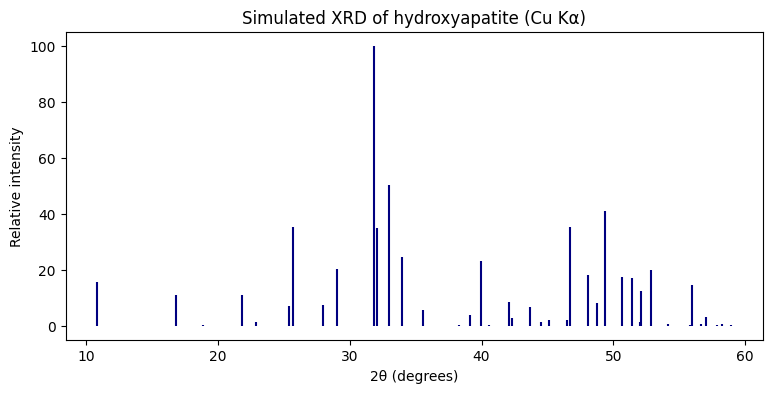

2θ = 31.82°, intensity = 100.0
2θ = 33.01°, intensity = 50.4
2θ = 49.33°, intensity = 40.8
2θ = 46.70°, intensity = 35.3
2θ = 25.71°, intensity = 35.1
2θ = 32.09°, intensity = 35.0


In [6]:
from pymatgen.analysis.diffraction.xrd import XRDCalculator
import matplotlib.pyplot as plt

calc = XRDCalculator(wavelength="CuKa")
pattern = calc.get_pattern(struct, two_theta_range=(10, 60))

plt.figure(figsize=(9, 4))
plt.vlines(pattern.x, 0, pattern.y, color="navy")
plt.xlabel("2θ (degrees)")
plt.ylabel("Relative intensity")
plt.title("Simulated XRD of hydroxyapatite (Cu Kα)")
plt.show()

top = sorted(zip(pattern.y, pattern.x), reverse=True)[:6]
for inten, angle in top:
    print(f"2θ = {angle:.2f}°, intensity = {inten:.1f}")

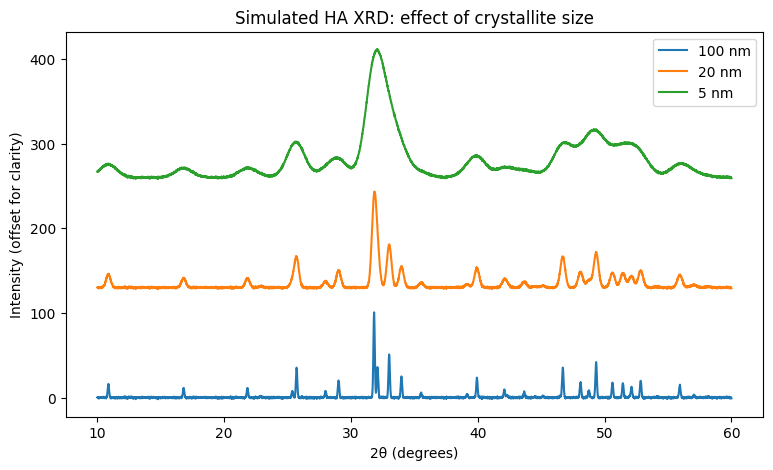

In [7]:
import numpy as np
import matplotlib.pyplot as plt

lam = calc.wavelength          # X-ray wavelength (Å) from Cell 3
K = 0.9                        # Scherrer constant
inst = 0.10                    # instrument broadening (degrees)
tt = np.linspace(10, 60, 5000)

def profile(L_nm, noise=0.5, seed=0):
    rng = np.random.default_rng(seed)
    y = np.zeros_like(tt)
    for x0, h in zip(pattern.x, pattern.y):
        th = np.radians(x0 / 2)
        beta = np.degrees(K * lam / (L_nm * 10 * np.cos(th)))
        fwhm = np.sqrt(beta**2 + inst**2)
        sig = fwhm / (2 * np.sqrt(2 * np.log(2)))
        y += h * np.exp(-0.5 * ((tt - x0) / sig) ** 2)
    return y + rng.normal(0, noise, tt.size)

plt.figure(figsize=(9, 5))
for L, off in [(100, 0), (20, 130), (5, 260)]:
    plt.plot(tt, profile(L) + off, label=f"{L} nm")
plt.xlabel("2θ (degrees)")
plt.ylabel("Intensity (offset for clarity)")
plt.title("Simulated HA XRD: effect of crystallite size")
plt.legend()
plt.show()

Peak used (002): 25.71 deg
True (nm) | FWHM (deg) | Estimated (nm) | Error (%)
        5 |      1.553 |            5.3 |      +5.2
       10 |      0.867 |            9.5 |      -5.4
       20 |      0.490 |           17.0 |     -15.0
       50 |      0.193 |           49.4 |      -1.3
      100 |      0.128 |          102.8 |      +2.8
      200 |      0.107 |          213.5 |      +6.8


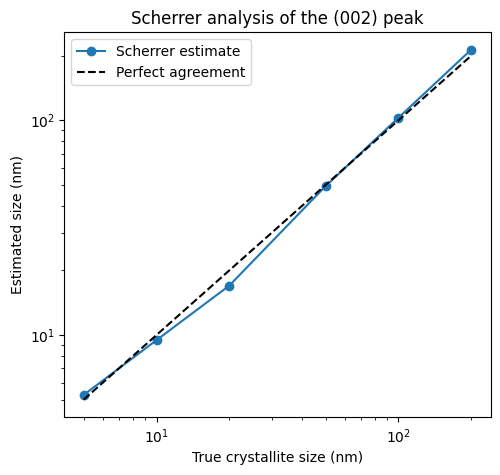

In [8]:
from scipy.optimize import curve_fit

def gauss(x, A, x0, s, c):
    return A * np.exp(-0.5 * ((x - x0) / s) ** 2) + c

target = pattern.x[np.argmin(abs(pattern.x - 25.7))]
print("Peak used (002):", round(target, 2), "deg")

def size_from_profile(y, window=1.5):
    m = (tt > target - window) & (tt < target + window)
    popt, _ = curve_fit(gauss, tt[m], y[m],
                        p0=[y[m].max(), target, 0.3, 0], maxfev=10000)
    fwhm = 2 * np.sqrt(2 * np.log(2)) * abs(popt[2])
    bs2 = fwhm**2 - inst**2          # remove instrument broadening
    if bs2 <= 0:
        return np.nan, fwhm
    beta = np.radians(np.sqrt(bs2))
    L = K * lam / (beta * np.cos(np.radians(popt[1] / 2))) / 10   # nm
    return L, fwhm

true_sizes = [5, 10, 20, 50, 100, 200]
est = []
print("True (nm) | FWHM (deg) | Estimated (nm) | Error (%)")
for L in true_sizes:
    e, fw = size_from_profile(profile(L))
    est.append(e)
    print(f"{L:>9} | {fw:10.3f} | {e:14.1f} | {100*(e-L)/L:+9.1f}")

plt.figure(figsize=(5.5, 5))
plt.loglog(true_sizes, est, "o-", label="Scherrer estimate")
plt.loglog(true_sizes, true_sizes, "k--", label="Perfect agreement")
plt.xlabel("True crystallite size (nm)")
plt.ylabel("Estimated size (nm)")
plt.title("Scherrer analysis of the (002) peak")
plt.legend()
plt.show()

In [9]:
import pandas as pd
from google.colab import files

# Figure 2: ideal simulated XRD
plt.figure(figsize=(9, 4))
plt.vlines(pattern.x, 0, pattern.y, color="navy")
plt.xlabel("2θ (degrees)")
plt.ylabel("Relative intensity")
plt.title("Simulated XRD of hydroxyapatite (Cu Kα)")
plt.savefig("fig2_simulated_XRD.png", dpi=300, bbox_inches="tight")
plt.close()

# Figure 3: effect of crystallite size
plt.figure(figsize=(9, 5))
for L, off in [(100, 0), (20, 130), (5, 260)]:
    plt.plot(tt, profile(L) + off, label=f"{L} nm")
plt.xlabel("2θ (degrees)")
plt.ylabel("Intensity (offset for clarity)")
plt.title("Simulated HA XRD: effect of crystallite size")
plt.legend()
plt.savefig("fig3_size_effect.png", dpi=300, bbox_inches="tight")
plt.close()

# Results table + Figure 4
rows = []
for L in true_sizes:
    e, fw = size_from_profile(profile(L))
    rows.append({"true_nm": L, "FWHM_deg": round(fw, 3),
                 "estimated_nm": round(e, 1),
                 "error_pct": round(100 * (e - L) / L, 1)})
df = pd.DataFrame(rows)
df.to_csv("scherrer_results.csv", index=False)
print(df)

plt.figure(figsize=(5.5, 5))
plt.loglog(df.true_nm, df.estimated_nm, "o-", label="Scherrer estimate")
plt.loglog(df.true_nm, df.true_nm, "k--", label="Perfect agreement")
plt.xlabel("True crystallite size (nm)")
plt.ylabel("Estimated size (nm)")
plt.title("Scherrer analysis of the (002) peak")
plt.legend()
plt.savefig("fig4_scherrer_test.png", dpi=300, bbox_inches="tight")
plt.close()

for f in ["fig2_simulated_XRD.png", "fig3_size_effect.png",
          "fig4_scherrer_test.png", "scherrer_results.csv"]:
    files.download(f)

   true_nm  FWHM_deg  estimated_nm  error_pct
0        5     1.553           5.3        5.2
1       10     0.867           9.5       -5.4
2       20     0.490          17.0      -15.0
3       50     0.193          49.4       -1.3
4      100     0.128         102.8        2.8
5      200     0.107         213.5        6.8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>